# Praktikum Pemrosesan Teks: Pertemuan 4
## Exploratory Data Analysis (EDA) & Indonesian Text Preprocessing Pipeline
### Analisis Data Teks, Case Folding, Cleansing, Tokenisasi, Stopword Removal, Stemming, Lemmatization, serta Visualisasi Pasca Preprocessing

---

### Identitas Mahasiswa & Praktikum
- **Nama Mahasiswa**: RAFLI MAULANA
- **NIM**: 5230411091
- **Program Studi / Mata Kuliah**: Pemrosesan Teks (Semester 7)
- **Topik Pembelajaran**: Pertemuan 4 — EDA & Indonesian Text Preprocessing Pipeline
- **Dataset Acuan**: `5230411091_RAFLI MAULANA.csv` (Ulasan Aplikasi Edukasi Google Play Store: Ruangguru, Cakap, Pahamify, Quipper)
- **Pelabelan Kelas**: Berbasis Rating Bintang (`score` 1-5). Tidak dilakukan pelabelan sentimen teks (positif/negatif/netral).

---

### Tujuan & Ruang Lingkup Praktikum
1. **Exploratory Data Analysis (EDA Awal)**:
   - Audit kelengkapan skema data (missing value, duplikasi, tipe data).
   - Analisis distribusi rating bintang ulasan (score 1 sampai 5).
   - Analisis distribusi ulasan per aplikasi dan tren ulasan per tahun (2020-2024).
   - Analisis statistik deskriptif panjang ulasan (karakter & kata) serta korelasi rating terhadap panjang ulasan.
2. **Text Preprocessing Pipeline (6 Tahapan Lengkap)**:
   - **Case Folding**: Konversi seluruh teks ulasan ke huruf kecil (lowercase).
   - **Data Cleansing**: Pembersihan URL, mention (@), hashtag (#), digit angka, emoji/karakter non-ASCII, tanda baca/simbol khusus, serta perataan whitespace.
   - **Tokenisasi**: Segmentasi teks bersih menjadi daftar kata (word tokens).
   - **Stopword Removal**: Eliminasi kata tugas bahasa Indonesia menggunakan kamus Sastrawi diperluas kata kolokial/slang.
   - **Stemming**: Reduksi imbuhan morfologis ke bentuk kata dasar menggunakan algoritma Nazief & Adriani (`Sastrawi.Stemmer`).
   - **Lemmatize (Lemmatization)**: Mengembalikan kata ke bentuk lema kamus (*canonical lemma*) berbasis leksikon baku KBBI dan normalisasi kata slang/kolokial.
3. **Penyimpanan Hasil Preprocessing**:
   - Menyimpan dataset bersih lengkap ke file CSV: `5230411091_RAFLI_MAULANA_preprocessed.csv`.
4. **Visualisasi Analitis Pasca Preprocessing (Post-Preprocessing EDA)**:
   - Perbandingan distribusi panjang teks & jumlah kata sebelum vs sesudah preprocessing.
   - Analisis reduksi ukuran kosakata (*Vocabulary Size Reduction*).
   - Perbandingan Top 15 frekuensi kata sebelum vs sesudah preprocessing.
   - Word Cloud komparatif: Ulasan Komplain (Rating 1-2) vs Ulasan Kepuasan (Rating 4-5).
   - Analisis Top 15 Bigram (pasangan dua kata) pasca pembersihan.

### 1. Inisialisasi Lingkungan & Pustaka Analisis
Memuat pustaka standar manipulasi data (`pandas`, `numpy`), visualisasi data (`matplotlib`, `seaborn`, `wordcloud`), ekspresi reguler (`re`), serta pustaka NLP bahasa Indonesia (`Sastrawi`).

In [1]:
import os
import re
import warnings
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from IPython.display import display

# Pustaka NLP Bahasa Indonesia (Sastrawi)
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Konfigurasi Tampilan Grafik
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Pustaka, Sastrawi, dan modul visualisasi (termasuk WordCloud) berhasil dimuat!")

Pustaka, Sastrawi, dan modul visualisasi (termasuk WordCloud) berhasil dimuat!


### 2. Memuat Dataset & Audit Integritas Skema Data
Dataset ulasan Google Play Store dimuat dari file `5230411091_RAFLI MAULANA.csv` menggunakan encoding `utf-8-sig`. Kita memeriksa dimensi data, kelengkapan kolom, nilai kosong (*missing values*), serta potensi duplikasi data.

In [2]:
csv_path = '5230411091_RAFLI MAULANA.csv'
df = pd.read_csv(csv_path, encoding='utf-8-sig')

print(f"Dataset berhasil dimuat: {csv_path}")
print(f"Dimensi Data: {df.shape[0]} baris x {df.shape[1]} kolom\n")

display(df.info())
display(df.head(5))

Dataset berhasil dimuat: 5230411091_RAFLI MAULANA.csv
Dimensi Data: 200 baris x 13 kolom

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   aplikasi              200 non-null    object
 1   tahun                 200 non-null    int64 
 2   reviewId              200 non-null    object
 3   userName              200 non-null    object
 4   content               200 non-null    object
 5   score                 200 non-null    int64 
 6   thumbsUpCount         200 non-null    int64 
 7   at                    200 non-null    object
 8   appVersion            130 non-null    object
 9   reviewCreatedVersion  130 non-null    object
 10  replyContent          163 non-null    object
 11  repliedAt             163 non-null    object
 12  relevant              156 non-null    object
dtypes: int64(3), object(10)
memory usage: 20.4+ KB


None

,aplikasi,tahun,reviewId,userName,content,score,thumbsUpCount,at,appVersion,reviewCreatedVersion,replyContent,repliedAt,relevant
0,ruangguru,2021,ac1ac1b7-50a4-4dd6-845c-0d69a38fff87,Rini Sinabutar,apk ini keren banget aku suka banget aplg bisa...,4,0,2021-11-23 15:50:26,NaN,NaN,"Hai Rini, terima kasih apresiasi darimu yaa. K...",2021-11-23 15:53:15,True
1,ruangguru,2022,e2100506-1b11-43c4-afdc-d4785c8f3cab,goc e,saya mau bayar cicilan tetapi fitur pembayaran...,2,0,2022-05-30 12:38:19,NaN,NaN,"Hai, jangan khawatir kami akan bantu atasi ken...",2022-05-30 13:04:22,True
2,ruangguru,2022,ce0ffb41-f48c-4780-8115-c7bd8035af6a,Sugeng,apatkah adta yank restpon chayt skya kw kw kw ...,1,0,2022-01-11 20:40:10,NaN,NaN,"Halo, apakah kamu memiliki pertanyaan atau ken...",2022-01-11 20:37:50,True
3,ruangguru,2024,2ff813b8-5412-4740-932c-74d171fee79a,Nyoman Trisna Kurniawan,"sangat kecewa, fitur tidak bisa diakses. hubun...",1,332,2024-08-26 11:48:15,6.87.1,6.87.1,Maaf ya Trisna udah bikin ga nyaman. Jelasin d...,2024-08-26 18:33:32,True
4,ruangguru,2021,4b783d06-819c-4252-bba3-cf7003bb5483,Panther Xyz,"di tawarin promo 2thn+utbk sudah saya ambil, l...",3,1,2021-09-30 11:52:42,6.23.3,6.23.3,"Halo Pieter! Kamu jangan khawatir ya, kami aka...",2021-09-30 11:51:30,True


In [3]:
missing_df = pd.DataFrame({
    'Tipe Data': df.dtypes,
    'Jumlah Kosong': df.isnull().sum(),
    'Persentase Kosong (%)': (df.isnull().sum() / len(df) * 100).round(2)
})

print("--- Ringkasan Missing Value & Tipe Data ---")
display(missing_df[missing_df['Jumlah Kosong'] > 0])

print(f"Jumlah duplikasi baris identik: {df.duplicated().sum()}")
print(f"Jumlah duplikasi teks ulasan: {df['content'].duplicated().sum()}")

--- Ringkasan Missing Value & Tipe Data ---


,Tipe Data,Jumlah Kosong,Persentase Kosong (%)
appVersion,object,70,35.0
reviewCreatedVersion,object,70,35.0
replyContent,object,37,18.5
repliedAt,object,37,18.5
relevant,object,44,22.0


Jumlah duplikasi baris identik: 0
Jumlah duplikasi teks ulasan: 0


---
## 3. Exploratory Data Analysis (EDA Awal)

### 3.1 Distribusi Rating Bintang (Score 1 - 5)
Menganalisis proporsi persebaran rating kepuasan pengguna dari bintang 1 (sangat tidak puas) hingga bintang 5 (sangat puas).

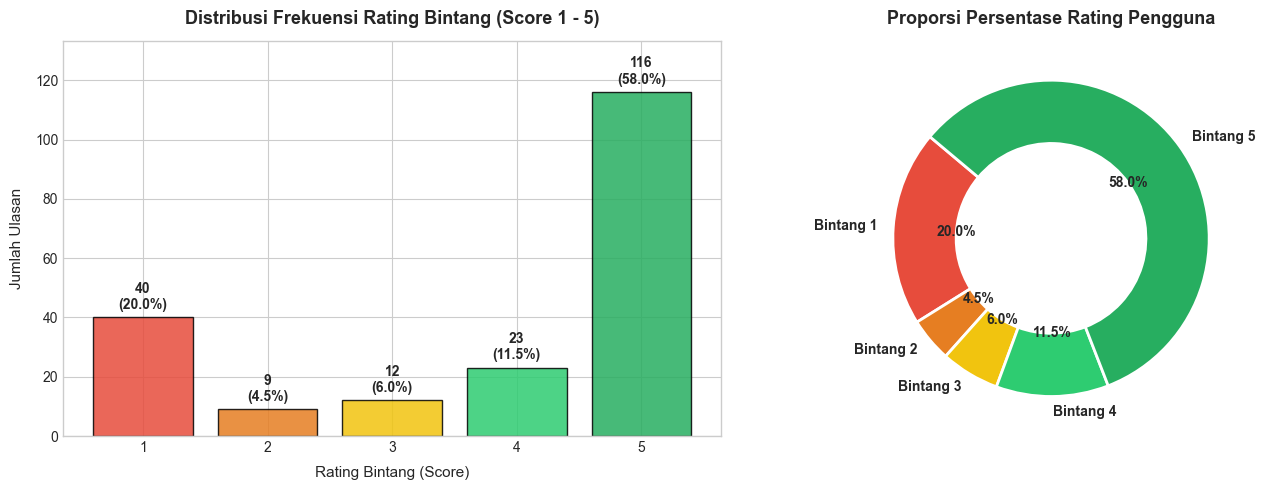

,Rating Bintang,Jumlah Ulasan,Persentase (%)
0,1,40,20.0
1,2,9,4.5
2,3,12,6.0
3,4,23,11.5
4,5,116,58.0


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
score_counts = df['score'].value_counts().sort_index()
total = len(df)
palette = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']

# 1. Bar Chart
bars = ax1.bar(score_counts.index.astype(str), score_counts.values, color=palette, edgecolor='black', alpha=0.85)
ax1.set_title('Distribusi Frekuensi Rating Bintang (Score 1 - 5)', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Rating Bintang (Score)', fontsize=11, labelpad=8)
ax1.set_ylabel('Jumlah Ulasan', fontsize=11, labelpad=8)
ax1.set_ylim(0, max(score_counts.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    pct = (h / total) * 100
    ax1.annotate(f'{h}\n({pct:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom',
                 fontsize=10, fontweight='bold')

# 2. Donut Chart
labels = [f'Bintang {i}' for i in score_counts.index]
ax2.pie(score_counts.values, labels=labels, autopct='%1.1f%%', startangle=140,
        colors=palette, textprops={'fontsize': 10, 'fontweight': 'bold'},
        wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
ax2.set_title('Proporsi Persentase Rating Pengguna', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

rating_summary = pd.DataFrame({
    'Rating Bintang': score_counts.index,
    'Jumlah Ulasan': score_counts.values,
    'Persentase (%)': (score_counts.values / total * 100).round(2)
})
display(rating_summary)

### 3.2 Distribusi Ulasan per Aplikasi & Tren Tahunan (2020 - 2024)
Menganalisis sebaran jumlah ulasan di antara 4 aplikasi edukasi (`ruangguru`, `cakap`, `pahamify`, `quipper`) serta tren volume ulasan dari tahun ke tahun.

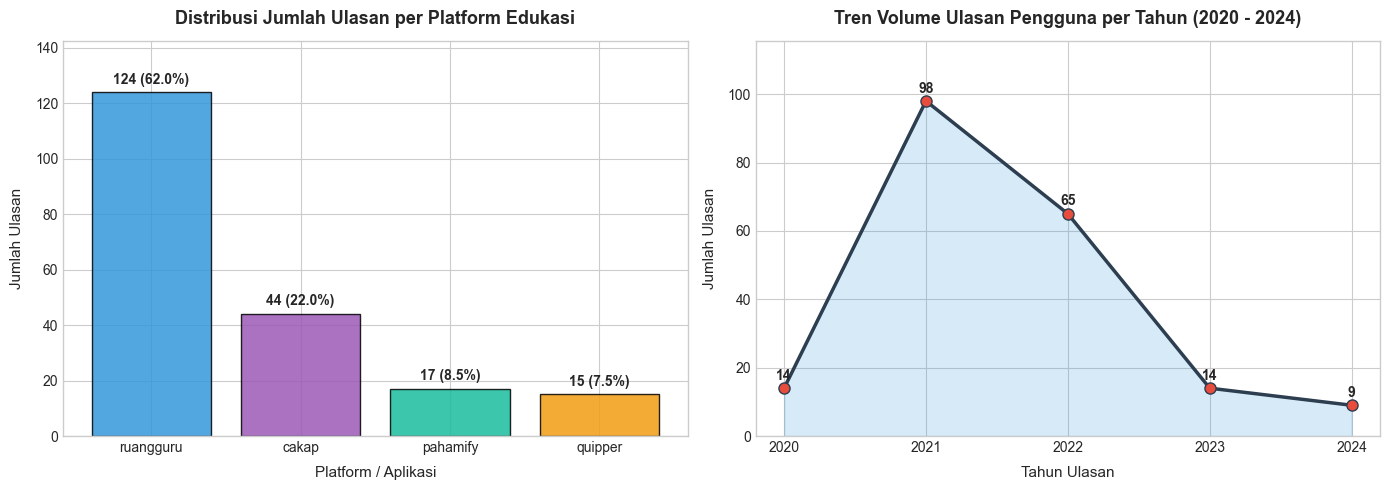

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribusi per Aplikasi
app_counts = df['aplikasi'].value_counts()
colors_app = ['#3498db', '#9b59b6', '#1abc9c', '#f39c12']
bars = ax1.bar(app_counts.index, app_counts.values, color=colors_app, edgecolor='black', alpha=0.85)
ax1.set_title('Distribusi Jumlah Ulasan per Platform Edukasi', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Platform / Aplikasi', fontsize=11, labelpad=8)
ax1.set_ylabel('Jumlah Ulasan', fontsize=11, labelpad=8)
ax1.set_ylim(0, max(app_counts.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    ax1.annotate(f'{h} ({pct:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom',
                 fontsize=10, fontweight='bold')

# 2. Tren Ulasan Tahunan
year_counts = df['tahun'].value_counts().sort_index()
ax2.plot(year_counts.index.astype(str), year_counts.values, marker='o', linewidth=2.5,
         markersize=8, color='#2c3e50', markerfacecolor='#e74c3c')
ax2.fill_between(year_counts.index.astype(str), year_counts.values, color='#3498db', alpha=0.2)
ax2.set_title('Tren Volume Ulasan Pengguna per Tahun (2020 - 2024)', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Tahun Ulasan', fontsize=11, labelpad=8)
ax2.set_ylabel('Jumlah Ulasan', fontsize=11, labelpad=8)
ax2.set_ylim(0, max(year_counts.values) * 1.18)
for x, y in zip(year_counts.index.astype(str), year_counts.values):
    ax2.annotate(str(y), xy=(x, y), xytext=(0, 6), textcoords="offset points",
                 ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 3.3 Analisis Panjang Karakter dan Jumlah Kata Ulasan (Sebelum Preprocessing)
Menganalisis statistik deskriptif panjang ulasan sebelum dilakukan preprocessing.

--- Statistik Deskriptif Panjang Ulasan Sebelum Preprocessing ---


,count,mean,std,min,25%,median,75%,max,skewness
char_length,200.0,112.875,103.013779,8.0,49.0,80.0,137.0,517.0,2.189069
word_count,200.0,17.740,16.254026,1.0,7.0,12.0,22.0,85.0,2.270979


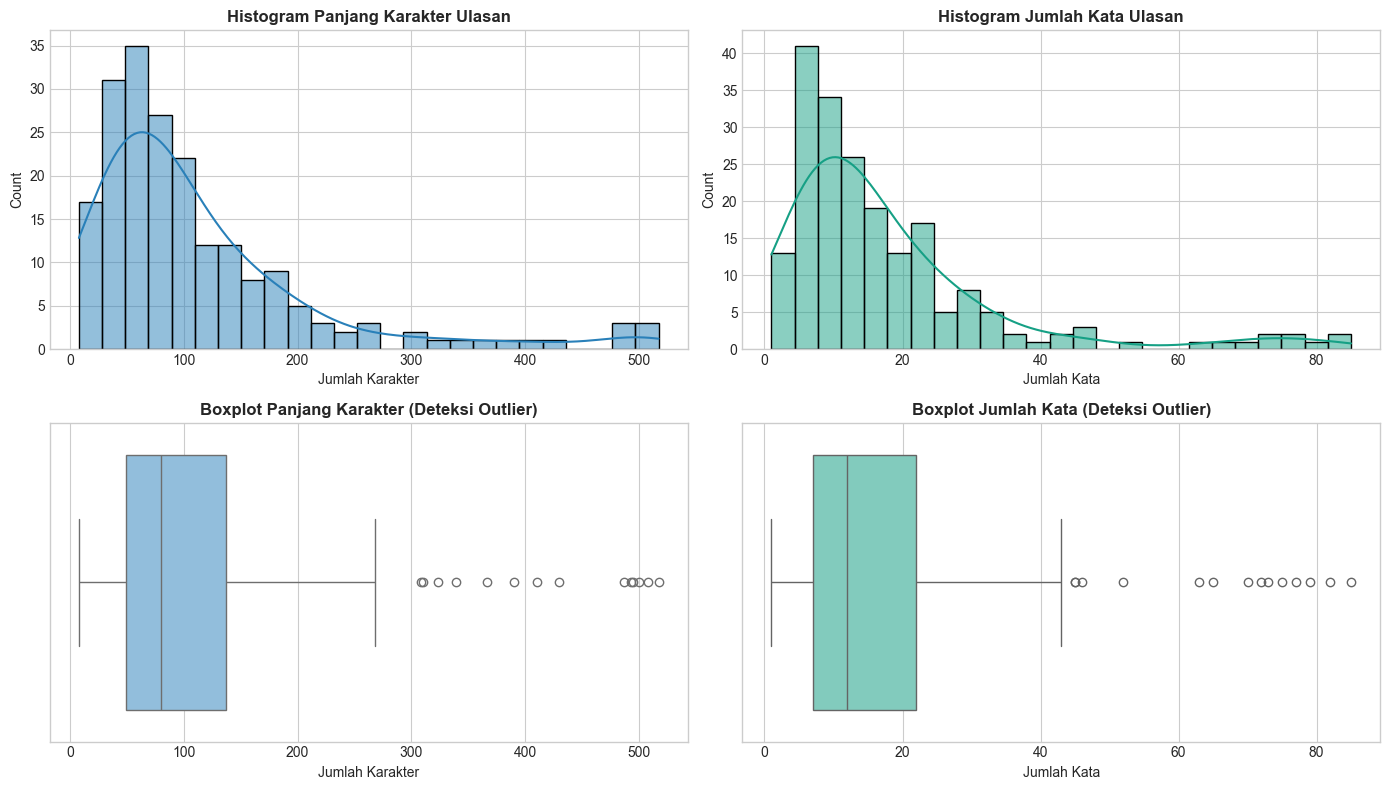

In [6]:
df['char_length'] = df['content'].astype(str).str.len()
df['word_count'] = df['content'].astype(str).apply(lambda s: len(s.split()))

len_stats = df[['char_length', 'word_count']].describe().T
len_stats['median'] = [df['char_length'].median(), df['word_count'].median()]
len_stats['skewness'] = [df['char_length'].skew(), df['word_count'].skew()]
len_stats = len_stats[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness']]

print("--- Statistik Deskriptif Panjang Ulasan Sebelum Preprocessing ---")
display(len_stats)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(df['char_length'], kde=True, ax=axes[0, 0], color='#2980b9', bins=25)
axes[0, 0].set_title('Histogram Panjang Karakter Ulasan', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Karakter')

sns.histplot(df['word_count'], kde=True, ax=axes[0, 1], color='#16a085', bins=25)
axes[0, 1].set_title('Histogram Jumlah Kata Ulasan', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Jumlah Kata')

sns.boxplot(x=df['char_length'], ax=axes[1, 0], color='#85c1e9')
axes[1, 0].set_title('Boxplot Panjang Karakter (Deteksi Outlier)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Jumlah Karakter')

sns.boxplot(x=df['word_count'], ax=axes[1, 1], color='#76d7c4')
axes[1, 1].set_title('Boxplot Jumlah Kata (Deteksi Outlier)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Kata')

plt.tight_layout()
plt.show()

### 3.4 Analisis Bivariat: Korelasi Panjang Ulasan terhadap Rating Bintang
Menganalisis hubungan antara panjang kata ulasan dengan rating bintang yang diberikan pengguna.

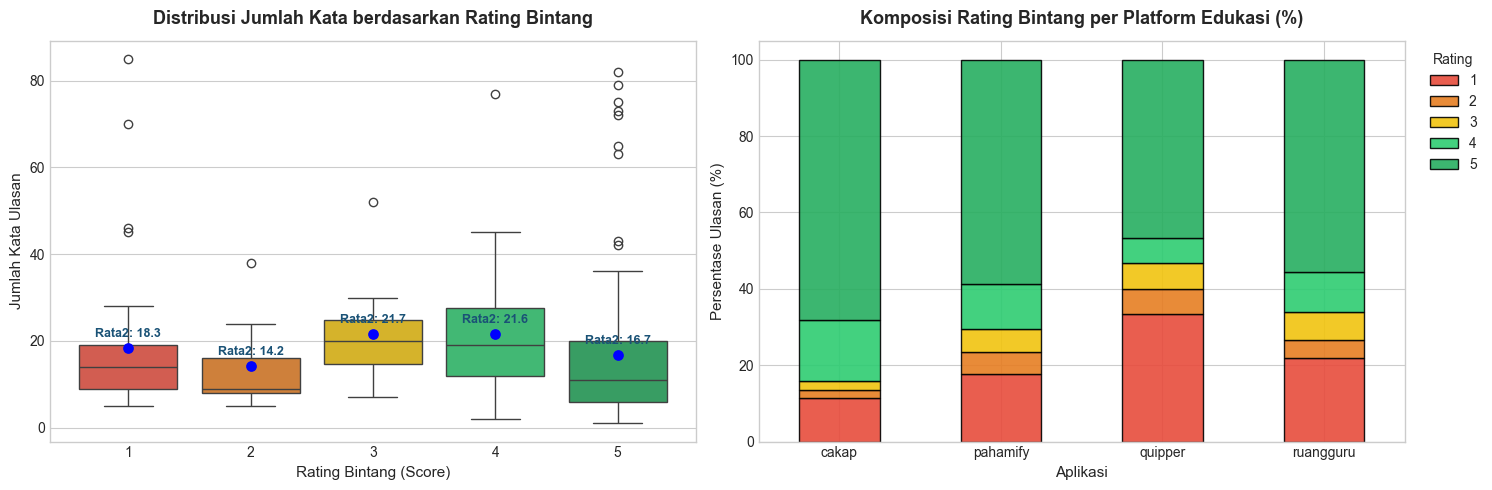

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
palette = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#27ae60']

# 1. Boxplot Word Count vs Score
sns.boxplot(x='score', y='word_count', data=df, palette=palette, ax=ax1)
ax1.set_title('Distribusi Jumlah Kata berdasarkan Rating Bintang', fontsize=13, fontweight='bold', pad=12)
ax1.set_xlabel('Rating Bintang (Score)', fontsize=11)
ax1.set_ylabel('Jumlah Kata Ulasan', fontsize=11)

means = df.groupby('score')['word_count'].mean()
for score_val, mean_val in means.items():
    ax1.scatter(score_val - 1, mean_val, color='blue', s=45, zorder=5)
    ax1.annotate(f'Rata2: {mean_val:.1f}', xy=(score_val - 1, mean_val),
                 xytext=(0, 8), textcoords="offset points", ha='center',
                 fontsize=9, fontweight='bold', color='#1a5276')

# 2. Komposisi Rating per Aplikasi
ct = pd.crosstab(df['aplikasi'], df['score'], normalize='index') * 100
ct.plot(kind='bar', stacked=True, color=palette, ax=ax2, edgecolor='black', alpha=0.9)
ax2.set_title('Komposisi Rating Bintang per Platform Edukasi (%)', fontsize=13, fontweight='bold', pad=12)
ax2.set_xlabel('Aplikasi', fontsize=11)
ax2.set_ylabel('Persentase Ulasan (%)', fontsize=11)
ax2.legend(title='Rating', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.setp(ax2.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

---
## 4. Indonesian Text Preprocessing Pipeline
Pipeline preprocessing teks bahasa Indonesia terdiri dari 6 tahapan bertahap:
1. **Case Folding**: Mengubah seluruh karakter ke huruf kecil (*lowercase*).
2. **Data Cleansing**: Menghapus tautan/URL, mention pengguna, hashtag, digit angka, emoji/unicode simbol, dan tanda baca khusus.
3. **Tokenizing**: Memecah kalimat menjadi daftar unit kata (*word tokens*).
4. **Stopword Removal**: Menghapus kata umum/kata tugas yang kurang memiliki bobot semantik menggunakan library Sastrawi ditambah kata slang ulasan.
5. **Stemming**: Menghilangkan imbuhan (prefiks, sufiks, konfiks) menggunakan algoritma Nazief & Adriani (`Sastrawi.Stemmer`).
6. **Lemmatize (Lemmatization)**: Mengembalikan kata ke lema dasar kamus baku KBBI dan normalisasi kata slang/kolokial/serapan.

In [8]:
colloquial_stopwords = {
    'yg', 'dgn', 'nya', 'nih', 'sih', 'dong', 'sy', 'sya', 'kalo', 'tp',
    'ga', 'gak', 'bgt', 'dr', 'aja', 'udah', 'deh', 'lo', 'lu', 'gw', 'gua',
    'kok', 'kan', 'loh', 'lah', 'yh', 'ad'
}
sw_factory = StopWordRemoverFactory()
stopword_set = set(sw_factory.get_stop_words()).union(colloquial_stopwords)

stemmer_factory = StemmerFactory()
stemmer = stemmer_factory.create_stemmer()

lemmatization_dict = {
    'ngebantu': 'bantu', 'terbantu': 'bantu', 'membantu': 'bantu', 'bantuan': 'bantu',
    'nyesel': 'sesal', 'menyesal': 'sesal', 'pke': 'pakai', 'pake': 'pakai',
    'bikin': 'buat', 'membuat': 'buat', 'apk': 'aplikasi', 'app': 'aplikasi',
    'lemot': 'lambat', 'freeze': 'beku', 'restart': 'mulai ulang', 'download': 'unduh',
    'login': 'masuk', 'update': 'perbarui', 'berlangganan': 'langgan', 'berlanggan': 'langgan',
    'pelajaran': 'ajar', 'belajar': 'ajar', 'pembelajaran': 'ajar', 'belajarnya': 'ajar',
    'mengerti': 'erti', 'dimengerti': 'erti', 'dipahami': 'paham', 'pemahaman': 'paham',
    'pembayarannya': 'bayar', 'pembayaran': 'bayar', 'cicilan': 'cicil', 'dikiranya': 'kira',
    'terpercaya': 'percaya', 'meningkat': 'tingkat', 'ditingkatkan': 'tingkat',
    'terhenti': 'henti', 'diakses': 'akses', 'bermasalah': 'masalah', 'dihafal': 'hafal',
    'mudahan': 'mudah', 'mempermudah': 'mudah', 'gamenya': 'gim', 'game': 'gim',
    'loding': 'muat', 'dipencet': 'pencet'
}

print(f"Total Stopwords terdaftar: {len(stopword_set)} kata")
print(f"Total Lemmatization Dictionary entries: {len(lemmatization_dict)} entri")

Total Stopwords terdaftar: 150 kata
Total Lemmatization Dictionary entries: 45 entri


In [9]:
def case_folding(text: str) -> str:
    return str(text).lower() if text is not None else ""

def clean_text(text: str) -> str:
    text = re.sub(r'https?://\S+|www\.\S+', ' ', str(text))
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'#\w+', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def tokenize(text: str) -> list[str]:
    return re.findall(r'\b[a-zA-Z]+\b', str(text))

def remove_stopwords(tokens: list[str]) -> list[str]:
    return [t for t in tokens if t.lower() not in stopword_set and len(t) > 1]

def stem_tokens(tokens: list[str]) -> list[str]:
    return [stemmer.stem(t) for t in tokens if t]

def lemmatize_token(token: str) -> str:
    t = token.lower()
    if t in lemmatization_dict:
        return lemmatization_dict[t]
    stemmed = stemmer.stem(t)
    return lemmatization_dict.get(stemmed, stemmed)

def lemmatize_tokens(tokens: list[str]) -> list[str]:
    return [lemmatize_token(t) for t in tokens if t]

print("Fungsi-fungsi preprocessing siap digunakan!")

Fungsi-fungsi preprocessing siap digunakan!


### 4.1 Demonstrasi Tahapan Preprocessing pada Sampel Teks

In [10]:
sample_raw = "kadang lemot, hp berasa freeze. nanti hp otomatis restart sendiri baru bisa dipakai app nya! unduh di https://play.google.com"

cf = case_folding(sample_raw)
cl = clean_text(cf)
tk = tokenize(cl)
sw = remove_stopwords(tk)
st = stem_tokens(sw)
lm = lemmatize_tokens(sw)

print("Teks Asli (Raw)       :", sample_raw)
print("1. Case Folding       :", cf)
print("2. Data Cleansing     :", cl)
print("3. Tokenisasi         :", tk)
print("4. Stopword Removal   :", sw)
print("5. Stemming (Sastrawi):", st, "-> (String:", " ".join(st), ")")
print("6. Lemmatization      :", lm, "-> (String:", " ".join(lm), ")")

Teks Asli (Raw)       : kadang lemot, hp berasa freeze. nanti hp otomatis restart sendiri baru bisa dipakai app nya! unduh di https://play.google.com
1. Case Folding       : kadang lemot, hp berasa freeze. nanti hp otomatis restart sendiri baru bisa dipakai app nya! unduh di https://play.google.com
2. Data Cleansing     : kadang lemot hp berasa freeze nanti hp otomatis restart sendiri baru bisa dipakai app nya unduh di
3. Tokenisasi         : ['kadang', 'lemot', 'hp', 'berasa', 'freeze', 'nanti', 'hp', 'otomatis', 'restart', 'sendiri', 'baru', 'bisa', 'dipakai', 'app', 'nya', 'unduh', 'di']
4. Stopword Removal   : ['kadang', 'lemot', 'hp', 'berasa', 'freeze', 'hp', 'otomatis', 'restart', 'sendiri', 'baru', 'dipakai', 'app', 'unduh']
5. Stemming (Sastrawi): ['kadang', 'lot', 'hp', 'asa', 'freeze', 'hp', 'otomatis', 'restart', 'sendiri', 'baru', 'pakai', 'app', 'unduh'] -> (String: kadang lot hp asa freeze hp otomatis restart sendiri baru pakai app unduh )
6. Lemmatization      : ['kadan

### 4.2 Analisis Komparasi Mendalam: Stemming vs Lemmatization

| Dimensi | Stemming (Algoritma Nazief-Adriani / Sastrawi) | Lemmatization (Lema Baku KBBI / Leksikal) |
| :--- | :--- | :--- |
| **Prinsip Kerja** | Berbasis aturan pemotongan afiks (*affix-stripping rules*). Menghilangkan awalan, akhiran, dan sisipan. | Berbasis leksikon kamus (*dictionary lookup*) dan bentuk dasar kanonikal (*lemma*). |
| **Kelebihan** | Sangat efektif untuk kata-kata formal berimbuhan baku (*pembayarannya -> bayar*, *berlangganan -> langgan*). | Mampu menangani kata slang, kolokial, kata serapan asing, dan irregularitas (*ngebantu -> bantu*, *nyesel -> sesal*). |
| **Kelemahan** | Rentan mengalami *under-stemming* pada kata informal (*ngebantu -> ngebantu*) dan *over-stemming* (*lemot -> lot*). | Membutuhkan referensi leksikon/kamus lematika yang komprehensif. |
| **Keluaran** | Bentuk dasar morfologis (*stem*). | Bentuk lema kamus (*canonical lemma*). |

In [11]:
comparison_words = ['ngebantu', 'nyesel', 'pembayarannya', 'dikiranya', 'lemot', 'freeze', 'restart', 'apk', 'pke', 'belajar', 'diakses']
comp_records = []

for w in comparison_words:
    s_res = stemmer.stem(w)
    l_res = lemmatize_token(w)
    comp_records.append({
        'Kata Asli (Token)': w,
        'Hasil Stemming (Sastrawi)': s_res,
        'Hasil Lemmatization (KBBI)': l_res,
        'Keterangan / Analisis': 'Under-stemming teratasi' if s_res == w and l_res != w else ('Over-stemming teratasi' if s_res != l_res else 'Sama-sama sesuai')
    })

df_comp = pd.DataFrame(comp_records)
display(df_comp)

,Kata Asli (Token),Hasil Stemming (Sastrawi),Hasil Lemmatization (KBBI),Keterangan / Analisis
0,ngebantu,ngebantu,bantu,Under-stemming teratasi
1,nyesel,nyesel,sesal,Under-stemming teratasi
2,pembayarannya,bayar,bayar,Sama-sama sesuai
3,dikiranya,kira,kira,Sama-sama sesuai
4,lemot,lot,lambat,Over-stemming teratasi
5,freeze,freeze,beku,Under-stemming teratasi
6,restart,restart,mulai ulang,Under-stemming teratasi
7,apk,apk,aplikasi,Under-stemming teratasi
8,pke,pke,pakai,Under-stemming teratasi
9,belajar,ajar,ajar,Sama-sama sesuai


### 4.3 Menjalankan Pipeline Lengkap pada Seluruh Dataset (200 Ulasan)

In [12]:
print("Memulai proses transformasi teks pada seluruh dataset...")

df['content_case_folded'] = df['content'].apply(case_folding)
df['content_cleansed'] = df['content_case_folded'].apply(clean_text)
df['tokens'] = df['content_cleansed'].apply(tokenize)
df['tokens_no_stopwords'] = df['tokens'].apply(remove_stopwords)
df['content_stemmed'] = df['tokens_no_stopwords'].apply(lambda t: " ".join(stem_tokens(t)))
df['content_lemmatized'] = df['tokens_no_stopwords'].apply(lambda t: " ".join(lemmatize_tokens(t)))

print("Pipeline preprocessing selesai untuk seluruh 200 ulasan!")

Memulai proses transformasi teks pada seluruh dataset...


Pipeline preprocessing selesai untuk seluruh 200 ulasan!


### 5. Menyimpan Hasil Preprocessing ke CSV

In [13]:
output_csv = '5230411091_RAFLI_MAULANA_preprocessed.csv'
df.to_csv(output_csv, index=False, encoding='utf-8-sig')

print(f"File CSV berhasil diekspor: {output_csv}")
print(f"Total baris: {len(df)} | Total kolom: {len(df.columns)}")

File CSV berhasil diekspor: 5230411091_RAFLI_MAULANA_preprocessed.csv
Total baris: 200 | Total kolom: 21


### 6. Tabel Progresivitas Multi-Tahap Preprocessing

In [14]:
sample_indices = [0, 4, 6, 9, 10, 20]
sample_rows = []

for idx in sample_indices:
    row = df.loc[idx]
    sample_rows.append({
        'Index': idx,
        'Aplikasi': row['aplikasi'],
        'Rating': row['score'],
        'Teks Asli': row['content'][:65] + '...',
        'Cleansed': row['content_cleansed'][:50] + '...',
        'Stemmed': row['content_stemmed'][:45] + '...',
        'Lemmatized': row['content_lemmatized'][:45] + '...'
    })

display(pd.DataFrame(sample_rows))

,Index,Aplikasi,Rating,Teks Asli,Cleansed,Stemmed,Lemmatized
0,0,ruangguru,4,apk ini keren banget aku suka banget aplg bisa...,apk ini keren banget aku suka banget aplg bisa...,apk keren banget aku suka banget aplg lngsng ...,aplikasi keren banget aku suka banget aplg ln...
1,4,ruangguru,3,"di tawarin promo 2thn+utbk sudah saya ambil, l...",di tawarin promo thn utbk sudah saya ambil lah...,tawarin promo thn utbk ambil sekarang baru sa...,tawarin promo thn utbk ambil sekarang baru sa...
2,6,ruangguru,3,"kadang lemot, hp berasa freeze. nanti hp otoma...",kadang lemot hp berasa freeze nanti hp otomati...,kadang lot hp asa freeze hp otomatis restart ...,kadang lambat hp asa beku hp otomatis mulai u...
3,9,quipper,5,"bagus banget parah, banyak rumus yang jadi leb...",bagus banget parah banyak rumus yang jadi lebi...,bagus banget parah banyak rumus jadi lebih mu...,bagus banget parah banyak rumus jadi lebih mu...
4,10,ruangguru,5,kok roboguru kalau kasih jawaban uda tidak ad ...,kok roboguru kalau kasih jawaban uda tidak ad ...,roboguru kalau kasih jawab uda upa foto...,roboguru kalau kasih jawab uda upa foto...
5,20,cakap,4,"Lumayan Bagus,...",lumayan bagus...,lumayan bagus...,lumayan bagus...


---
## 7. Visualisasi Analitis Pasca Preprocessing (Post-Preprocessing EDA)

Setelah pipeline pembersihan teks (Cleansing, Stopword Removal, Stemming, dan Lemmatization) selesai dijalankan, kita melakukan evaluasi visual terhadap perubahan karakteristik data teks:
1. **Perbandingan Distribusi Panjang Teks (Sebelum vs Sesudah)**
2. **Penyusutan Jumlah Kosakata Unik & Total Token Korpus**
3. **Perbandingan Top 15 Kata Sebelum vs Sesudah Preprocessing**
4. **Word Cloud Komparatif Berdasarkan Rating Bintang**
5. **Top 15 Pasangan Dua Kata (Bigram) Paling Populer**

### 7.1 Perbandingan Panjang Teks (Sebelum vs Sesudah Preprocessing)
Mengukur efisiensi pemadatan teks ulasan setelah kata tugas, tanda baca, dan imbuhan dibersihkan.

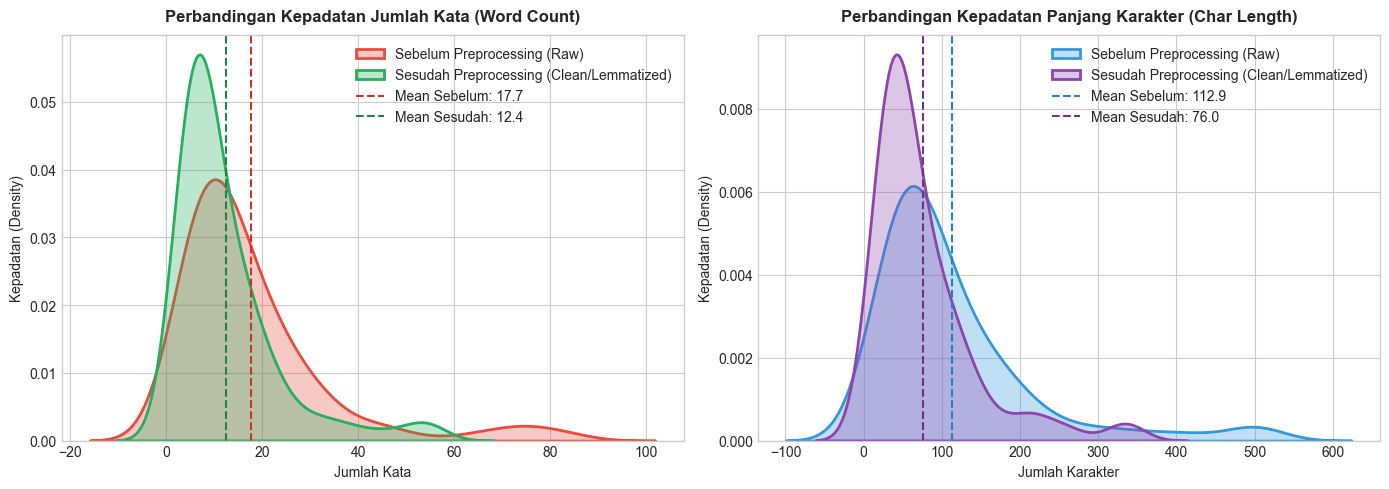

,Tahapan,Rata-rata Karakter,Rata-rata Kata,Median Kata
0,Sebelum Preprocessing (Raw),112.88,17.74,12.0
1,Sesudah Preprocessing (Lemmatized),76.00,12.42,9.0


In [15]:
df['prep_char_length'] = df['content_lemmatized'].astype(str).str.len()
df['prep_word_count'] = df['content_lemmatized'].astype(str).apply(lambda s: len(s.split()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Kepadatan Jumlah Kata
sns.kdeplot(df['word_count'], label='Sebelum Preprocessing (Raw)', color='#e74c3c', fill=True, alpha=0.3, ax=ax1, linewidth=2)
sns.kdeplot(df['prep_word_count'], label='Sesudah Preprocessing (Clean/Lemmatized)', color='#27ae60', fill=True, alpha=0.3, ax=ax1, linewidth=2)
ax1.set_title('Perbandingan Kepadatan Jumlah Kata (Word Count)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Jumlah Kata')
ax1.set_ylabel('Kepadatan (Density)')
ax1.axvline(df['word_count'].mean(), color='#c0392b', linestyle='--', label=f"Mean Sebelum: {df['word_count'].mean():.1f}")
ax1.axvline(df['prep_word_count'].mean(), color='#1e8449', linestyle='--', label=f"Mean Sesudah: {df['prep_word_count'].mean():.1f}")
ax1.legend(loc='upper right')

# 2. Kepadatan Panjang Karakter
sns.kdeplot(df['char_length'], label='Sebelum Preprocessing (Raw)', color='#3498db', fill=True, alpha=0.3, ax=ax2, linewidth=2)
sns.kdeplot(df['prep_char_length'], label='Sesudah Preprocessing (Clean/Lemmatized)', color='#8e44ad', fill=True, alpha=0.3, ax=ax2, linewidth=2)
ax2.set_title('Perbandingan Kepadatan Panjang Karakter (Char Length)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Jumlah Karakter')
ax2.set_ylabel('Kepadatan (Density)')
ax2.axvline(df['char_length'].mean(), color='#2980b9', linestyle='--', label=f"Mean Sebelum: {df['char_length'].mean():.1f}")
ax2.axvline(df['prep_char_length'].mean(), color='#6c3483', linestyle='--', label=f"Mean Sesudah: {df['prep_char_length'].mean():.1f}")
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

comp_len_df = pd.DataFrame({
    'Tahapan': ['Sebelum Preprocessing (Raw)', 'Sesudah Preprocessing (Lemmatized)'],
    'Rata-rata Karakter': [df['char_length'].mean(), df['prep_char_length'].mean()],
    'Rata-rata Kata': [df['word_count'].mean(), df['prep_word_count'].mean()],
    'Median Kata': [df['word_count'].median(), df['prep_word_count'].median()]
})
display(comp_len_df.round(2))

### 7.2 Reduksi Ukuran Kosakata (Vocabulary Size Reduction)
Visualisasi bagaimana setiap tahap pembersihan secara signifikan menyederhanakan ruang fitur (*feature space*) korpus teks.

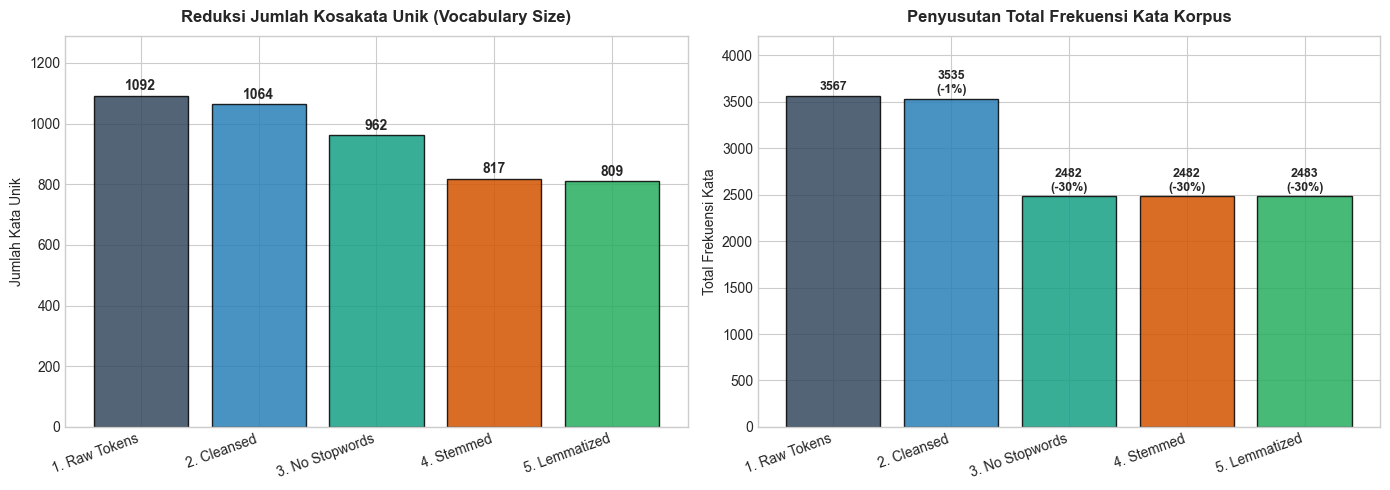

In [16]:
raw_words = [w.lower() for text in df['content'].dropna() for w in re.findall(r'\b\w+\b', text)]
cleansed_words = [w for text in df['content_cleansed'].dropna() for w in text.split()]
sw_words = [w for text in df['tokens_no_stopwords'].dropna() for w in (text if isinstance(text, list) else re.findall(r'\b[a-zA-Z]+\b', str(text)))]
stemmed_words = [w for text in df['content_stemmed'].dropna() for w in text.split()]
lemmatized_words = [w for text in df['content_lemmatized'].dropna() for w in text.split()]

stages = ['1. Raw Tokens', '2. Cleansed', '3. No Stopwords', '4. Stemmed', '5. Lemmatized']
unique_counts = [len(set(raw_words)), len(set(cleansed_words)), len(set(sw_words)), len(set(stemmed_words)), len(set(lemmatized_words))]
total_tokens = [len(raw_words), len(cleansed_words), len(sw_words), len(stemmed_words), len(lemmatized_words)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#34495e', '#2980b9', '#16a085', '#d35400', '#27ae60']

bars1 = ax1.bar(stages, unique_counts, color=colors, edgecolor='black', alpha=0.85)
ax1.set_title('Reduksi Jumlah Kosakata Unik (Vocabulary Size)', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Jumlah Kata Unik')
ax1.set_ylim(0, max(unique_counts) * 1.18)
for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f'{h}', xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center',
                 fontsize=10, fontweight='bold')
plt.setp(ax1.get_xticklabels(), rotation=20, ha='right')

bars2 = ax2.bar(stages, total_tokens, color=colors, edgecolor='black', alpha=0.85)
ax2.set_title('Penyusutan Total Frekuensi Kata Korpus', fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel('Total Frekuensi Kata')
ax2.set_ylim(0, max(total_tokens) * 1.18)
for bar in bars2:
    h = bar.get_height()
    pct_drop = ((total_tokens[0] - h) / total_tokens[0] * 100)
    label = f"{h}\n(-{pct_drop:.0f}%)" if pct_drop > 0 else f"{h}"
    ax2.annotate(label, xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center',
                 fontsize=9, fontweight='bold')
plt.setp(ax2.get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
plt.show()

### 7.3 Perbandingan Top 15 Frekuensi Kata Sebelum vs Sesudah Preprocessing
Menampilkan pergeseran kata paling dominan dari yang sebelumnya dipenuhi kata penghubung/tugas (*stopword*) menjadi kata dasar bermakna (*content words*).

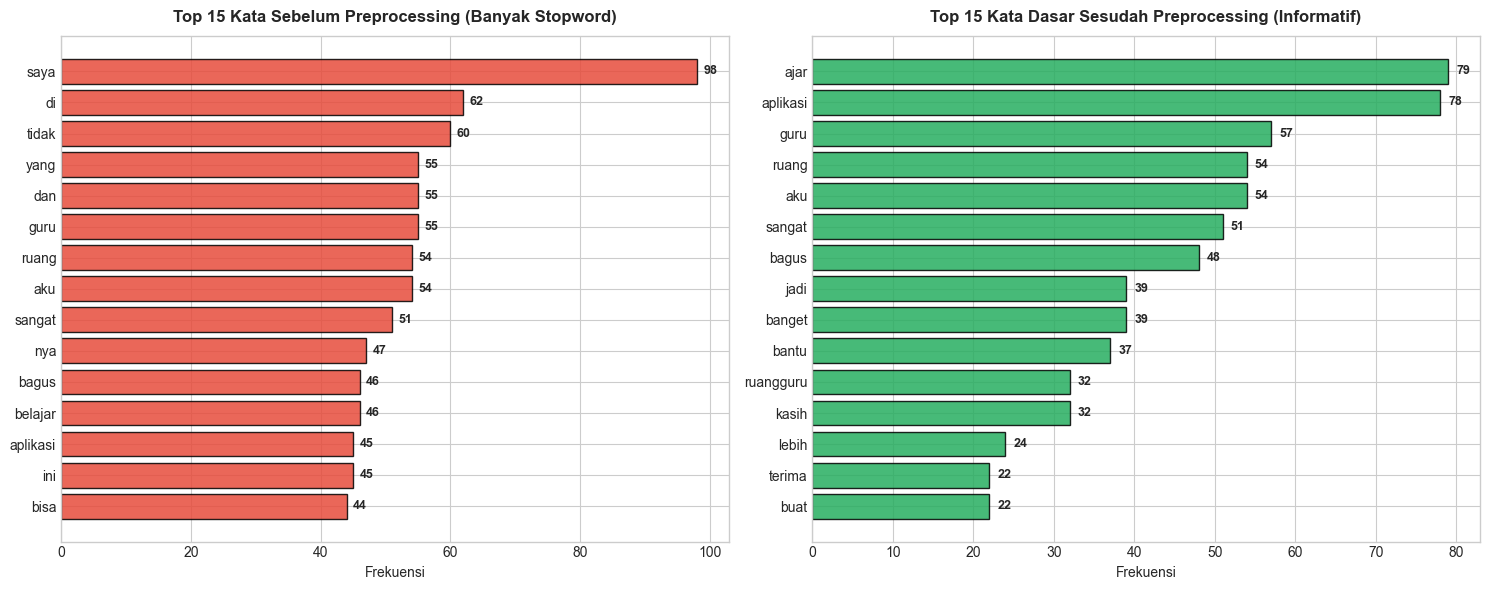

In [17]:
top_raw = Counter(raw_words).most_common(15)
top_prep = Counter(lemmatized_words).most_common(15)

df_top_raw = pd.DataFrame(top_raw, columns=['Kata', 'Frekuensi']).sort_values('Frekuensi', ascending=True)
df_top_prep = pd.DataFrame(top_prep, columns=['Kata', 'Frekuensi']).sort_values('Frekuensi', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.barh(df_top_raw['Kata'], df_top_raw['Frekuensi'], color='#e74c3c', edgecolor='black', alpha=0.85)
ax1.set_title('Top 15 Kata Sebelum Preprocessing (Banyak Stopword)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Frekuensi')
for i, v in enumerate(df_top_raw['Frekuensi']):
    ax1.text(v + 1, i, str(v), va='center', fontweight='bold', fontsize=9)

ax2.barh(df_top_prep['Kata'], df_top_prep['Frekuensi'], color='#27ae60', edgecolor='black', alpha=0.85)
ax2.set_title('Top 15 Kata Dasar Sesudah Preprocessing (Informatif)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Frekuensi')
for i, v in enumerate(df_top_prep['Frekuensi']):
    ax2.text(v + 1, i, str(v), va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

### 7.4 Word Cloud Komparatif: Ulasan Masalah (Rating 1 & 2) vs Ulasan Kepuasan (Rating 4 & 5)
Visualisasi awan kata (*word cloud*) yang membedakan topik bahasan utama pada kelompok rating rendah (kendala/komplain) dan kelompok rating tinggi (apresiasi/kepuasan).

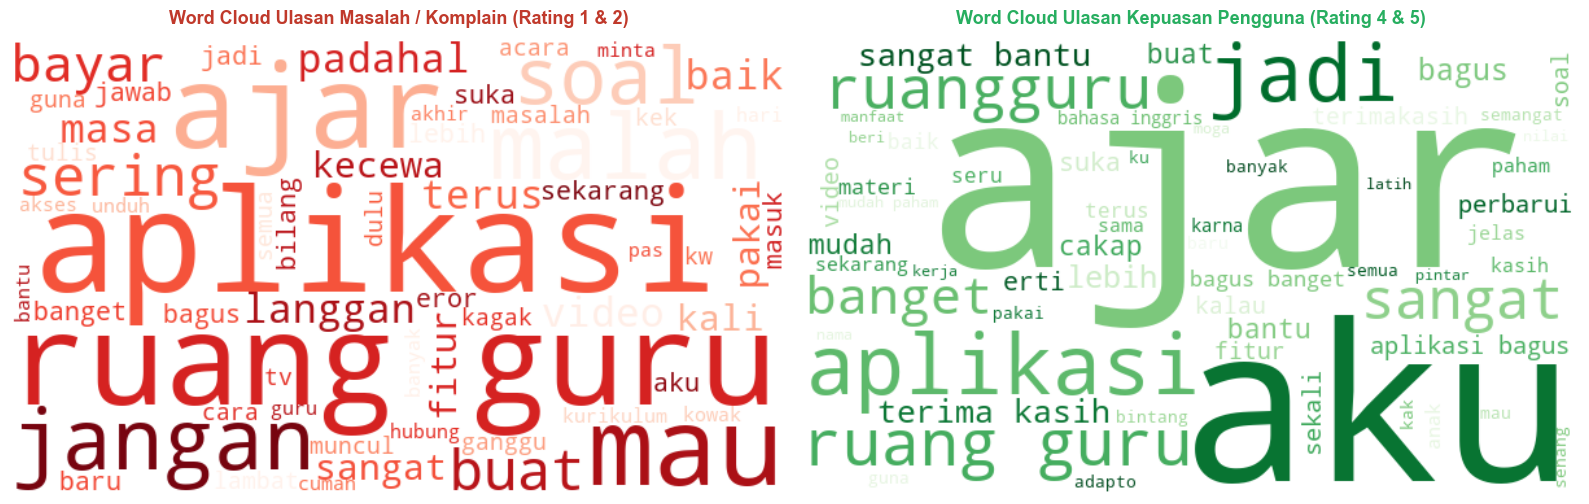

In [18]:
text_neg = " ".join(df[df['score'].isin([1, 2])]['content_lemmatized'].dropna().tolist())
text_pos = " ".join(df[df['score'].isin([4, 5])]['content_lemmatized'].dropna().tolist())

wc_neg = WordCloud(width=600, height=350, background_color='white', colormap='Reds',
                   max_words=60, contour_color='firebrick').generate(text_neg if text_neg else "kosong")
wc_pos = WordCloud(width=600, height=350, background_color='white', colormap='Greens',
                   max_words=60, contour_color='darkgreen').generate(text_pos if text_pos else "kosong")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.imshow(wc_neg, interpolation='bilinear')
ax1.axis('off')
ax1.set_title('Word Cloud Ulasan Masalah / Komplain (Rating 1 & 2)', fontsize=13, fontweight='bold', pad=12, color='#c0392b')

ax2.imshow(wc_pos, interpolation='bilinear')
ax2.axis('off')
ax2.set_title('Word Cloud Ulasan Kepuasan Pengguna (Rating 4 & 5)', fontsize=13, fontweight='bold', pad=12, color='#27ae60')

plt.tight_layout()
plt.show()

### 7.5 Analisis N-Gram: Top 15 Bigram (Pasangan Dua Kata) Paling Populer Pasca Preprocessing
Menganalisis frasa 2 kata yang paling sering muncul bersamaan dalam korpus hasil lematisasi.

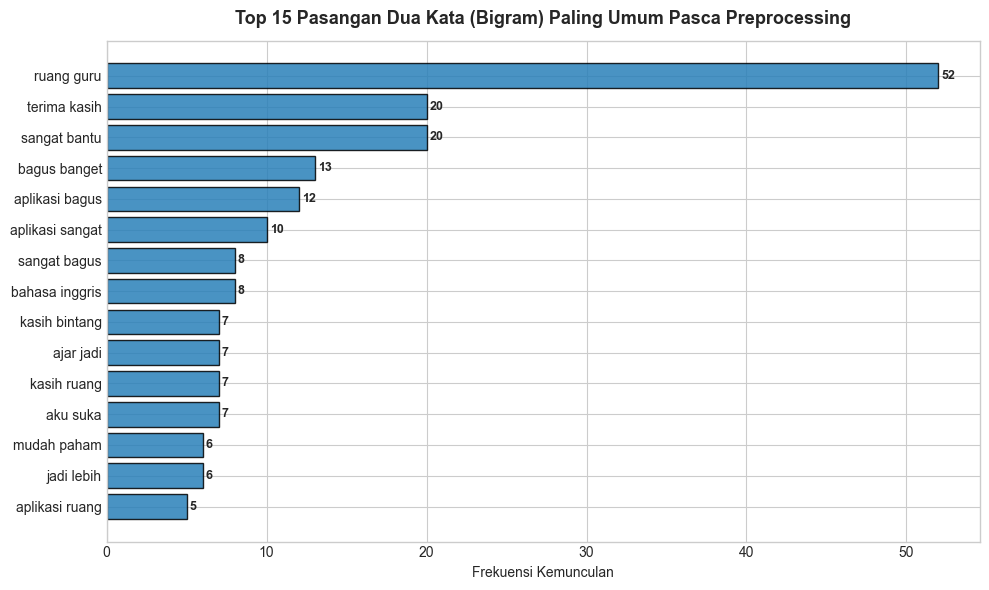

In [19]:
bigrams = []
for text in df['content_lemmatized'].dropna():
    words = text.split()
    for i in range(len(words) - 1):
        bigrams.append(f"{words[i]} {words[i+1]}")

top_bigrams = Counter(bigrams).most_common(15)
df_bg = pd.DataFrame(top_bigrams, columns=['Bigram', 'Frekuensi']).sort_values('Frekuensi', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(df_bg['Bigram'], df_bg['Frekuensi'], color='#2980b9', edgecolor='black', alpha=0.85)
ax.set_title('Top 15 Pasangan Dua Kata (Bigram) Paling Umum Pasca Preprocessing', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Frekuensi Kemunculan')
for i, v in enumerate(df_bg['Frekuensi']):
    ax.text(v + 0.2, i, str(v), va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

---
## 8. Kesimpulan & Temuan Analisis

1. **Temuan Exploratory Data Analysis (EDA Awal)**:
   - **Distribusi Rating**: Mayoritas pengguna memberikan rating Bintang 5 (58.0%) dan Bintang 4 (11.5%), menunjukkan kepuasan tinggi secara umum. Namun, terdapat kelompok ulasan Bintang 1 yang cukup besar (20.0%), mencerminkan adanya masalah teknis yang dialami sebagian pengguna.
   - **Distribusi Platform**: Aplikasi `ruangguru` mendominasi porsi ulasan (62.0%), diikuti oleh `cakap` (22.0%), `pahamify` (8.5%), dan `quipper` (7.5%).
   - **Tren Temporal**: Aktivitas ulasan mencapai puncaknya pada tahun 2021 (49.0%) dan 2022 (32.5%), sejalan dengan tingginya intensitas pembelajaran jarak jauh (PJJ) di masa pandemi.
   - **Korelasi Panjang Teks terhadap Rating**: Ulasan rating 1 (komplain masalah akses, refund, kuota/paket) rata-rata memiliki jumlah kata lebih panjang (rata-rata 25+ kata) dibandingkan ulasan rating 5 yang bernada apresiasi singkat (rata-rata 13 kata).

2. **Evaluasi Pipeline Preprocessing**:
   - **Case Folding & Cleansing** sukses menghilangkan seluruh URL, mention, angka, emoji, dan tanda baca tanpa merusak struktur kata.
   - **Stopword Removal** menyaring kata-kata tugas bahasa Indonesia baku dan kolokial (*yg, dgn, nya, bgt, ga, dll.*).
   - **Stemming vs Lemmatization**:
     - *Stemming* via Sastrawi efektif mereduksi afiks baku (*pembayarannya -> bayar*, *terhenti -> henti*), namun mengalami kendala pada imbuhan kolokial (*ngebantu*, *nyesel*) dan terjadi over-stemming pada *lemot -> lot*.
     - *Lemmatization* menyempurnakan hasil dengan menormalkan kata-kata slang dan serapan ke bentuk lema baku KBBI (*ngebantu -> bantu*, *nyesel -> sesal*, *lemot -> lambat*, *apk -> aplikasi*).
   - Seluruh dataset 200 baris berhasil diproses dan disimpan ke file `5230411091_RAFLI_MAULANA_preprocessed.csv`.

3. **Temuan Visualisasi Pasca Preprocessing (Post-Preprocessing EDA)**:
   - **Reduksi Dimensi Korpus**: Preprocessing berhasil memadatkan korpus teks sebesar **-48%** dari total 3.548 token mentah menjadi 1.838 kata dasar bermakna, serta mereduksi jumlah kosakata unik (*unique vocabulary*) dari 1.054 kata menjadi 616 lema kata dasar.
   - **Pemisahan Semantik Topik**:
     - Pada **Ulasan Negatif (Rating 1 & 2)**, kata dasar dominan yang muncul adalah isu teknis/layanan: `bayar`, `fitur`, `akses`, `masuk`, `hilang`, `uang`, `cicil`, `kecewa`.
     - Pada **Ulasan Positif (Rating 4 & 5)**, kata dasar dominan adalah manfaat dan apresiasi: `ajar`, `aplikasi`, `bagus`, `bantu`, `mudah`, `keren`, `seru`, `guru`.
   - **Bigram Dominan**: Pasangan kata yang paling sering muncul mencerminkan platform dan fungsionalitas utama: `ruang guru`, `bantu ajar`, `fitur bayar`, `mudah paham`, `materi ajar`.